# State-capacity test: same-province vs other-province upwind fire

Indonesia's fire response is organized by province. Under Presidential Instruction 3/2020, each governor commands a provincial fire task force with the regional military commander (Pangdam) and regional police chief (Kapolda) as deputy commanders, and district task forces include the district military commander and police chief. Fires inside a district's own province therefore draw on that district's security forces; smoke from fires in another province does not.

This gives a test that separates the explanations in `mechanisms.ipynb`:

- **State-capacity diversion** predicts that events carried out by state forces respond mainly to upwind fire in the *same* province.
- **Smoke and avoidance** predict that the source province does not matter: smoke is smoke.

The upwind instrument is rebuilt exactly as in `wind-IV.ipynb` (300 km, ±45°), but each upwind fire's FRP is assigned to the same-province or other-province component according to the province of the district it burns in. Because same-province fires are on average closer, a second split by distance (0–150 km and 150–300 km) is estimated jointly, so that the province contrast is not simply a distance contrast.

In [1]:
import warnings, gc
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import pyfixest as pf
import matplotlib.pyplot as plt
from scipy import stats
from scipy.spatial import cKDTree
warnings.filterwarnings('ignore')

ROOT = '/Users/hariaksha/Documents/GitHub/climate-conflict'
WIND_NC = f'{ROOT}/data/climate/wind/era5_wind_indonesia_2015_2025.nc'
FIRE_CSV = f'{ROOT}/data/climate/fire/DL_FIRE_SUOMI-VIIRS-C2_718931_Nov2000-Feb2026_buffer0km-csv/fire_archive_SV-C2_718931.csv'
ACLED_XLSX = f'{ROOT}/data/unrest/ACLED Data_2026-06-10.xlsx'
DISTRICT_SHP = f'{ROOT}/data/administrative/gadm41_IDN_shp/gadm41_IDN_2.shp'
PANEL_CSV = f'{ROOT}/analysis/iv_panel_district.csv'
OUT_INSTR = f'{ROOT}/analysis/output/upwind_instrument_by_province.csv'
OUT_CSV = f'{ROOT}/analysis/output/province_split_results.csv'
OUT_PNG = f'{ROOT}/analysis/output/province_split_coefplot.png'
FIG_PNG = f'{ROOT}/paper/figures/province_split_coefplot.png'

UPWIND_RADIUS_KM, UPWIND_HALF_ANG, NEAR_KM = 300, 45, 150
START_YEAR, END_YEAR, END_MONTH = 2015, 2025, 6
R_EARTH = 6371.0
FE, VCOV = 'district + year_month', {'CRV1': 'province'}

## 1. Districts, wind and fires (identical to `wind-IV.ipynb`, Sections 2–4)

In [2]:
districts_gdf = gpd.read_file(DISTRICT_SHP)[['NAME_1', 'NAME_2', 'TYPE_2', 'geometry']].rename(
    columns={'NAME_1': 'province', 'NAME_2': 'district'})
dup = districts_gdf['district'].duplicated(keep=False)
districts_gdf.loc[dup, 'district'] = districts_gdf.loc[dup, 'district'] + ' (' + districts_gdf.loc[dup, 'province'] + ')'
rp = districts_gdf.geometry.representative_point()
districts_gdf['dist_lat'], districts_gdf['dist_lon'] = rp.y, rp.x
district_to_prov = dict(zip(districts_gdf['district'], districts_gdf['province']))

ds = xr.open_dataset(WIND_NC)
if 'valid_time' in ds.coords:
    ds = ds.rename({'valid_time': 'time'})
u_df = ds['u10'].to_dataframe(name='u10').reset_index()
v_df = ds['v10'].to_dataframe(name='v10').reset_index()
wind_df = u_df.merge(v_df, on=['time', 'latitude', 'longitude'])
wind_df['time'] = pd.to_datetime(wind_df['time'])
wind_df['year'], wind_df['month'] = wind_df['time'].dt.year, wind_df['time'].dt.month
wind_df = wind_df[(wind_df['year'] >= START_YEAR) & ~((wind_df['year'] == END_YEAR) & (wind_df['month'] > END_MONTH))]

grid_points = wind_df[['latitude', 'longitude']].drop_duplicates().reset_index(drop=True)
gg = gpd.GeoDataFrame(grid_points, geometry=gpd.points_from_xy(grid_points['longitude'], grid_points['latitude']), crs='EPSG:4326')
grid_points['district'] = gpd.sjoin(gg, districts_gdf[['district', 'geometry']], how='left', predicate='within')['district'].values
have = set(grid_points['district'].dropna().unique())
missing = districts_gdf[~districts_gdf['district'].isin(have)]
if len(missing):
    _, nn = cKDTree(grid_points[['latitude', 'longitude']].values).query(missing[['dist_lat', 'dist_lon']].values)
    fb = grid_points.iloc[nn][['latitude', 'longitude']].reset_index(drop=True).copy()
    fb['district'] = missing['district'].values
    grid_points = pd.concat([grid_points.dropna(subset=['district']), fb], ignore_index=True)
else:
    grid_points = grid_points.dropna(subset=['district'])
dw = wind_df.merge(grid_points, on=['latitude', 'longitude'], how='inner')
dw = dw.groupby(['district', 'year', 'month']).agg(u=('u10', 'mean'), v=('v10', 'mean')).reset_index()
dw['wind_dir_from'] = (np.degrees(np.arctan2(dw['u'], dw['v'])) + 180) % 360

fires = pd.read_csv(FIRE_CSV, usecols=['acq_date', 'latitude', 'longitude', 'frp', 'confidence', 'type'],
                    dtype={'confidence': str, 'type': int})
fires = fires[(fires['type'] == 0) & fires['confidence'].isin(['h', 'n'])].copy()
fires['acq_date'] = pd.to_datetime(fires['acq_date'])
fires['year'], fires['month'] = fires['acq_date'].dt.year, fires['acq_date'].dt.month
fires = fires[(fires['year'] >= START_YEAR) & ~((fires['year'] == END_YEAR) & (fires['month'] > END_MONTH))]
fg = gpd.GeoDataFrame(fires, geometry=gpd.points_from_xy(fires['longitude'], fires['latitude']), crs='EPSG:4326')
fires['district'] = gpd.sjoin(fg, districts_gdf[['district', 'geometry']], how='left', predicate='within')['district'].values
fires = fires.dropna(subset=['district']).copy()
fires['fprov'] = fires['district'].map(district_to_prov)
print(f'District-month wind obs: {len(dw):,}; fire detections: {len(fires):,}')

District-month wind obs: 63,252; fire detections: 2,035,256


## 2. Rebuild the upwind instrument, split by source province and distance

In [3]:
def to_cart(lat, lon):
    la, lo = np.radians(lat), np.radians(lon)
    return np.column_stack([np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)])
def hav(lat1, lon1, lat2, lon2):
    dlat, dlon = np.radians(lat2 - lat1), np.radians(lon2 - lon1)
    a = np.sin(dlat / 2)**2 + np.cos(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.sin(dlon / 2)**2
    return R_EARTH * 2 * np.arcsin(np.sqrt(a))
def bearing(lat1, lon1, lat2, lon2):
    dlon = np.radians(lon2 - lon1)
    x = np.sin(dlon) * np.cos(np.radians(lat2))
    y = np.cos(np.radians(lat1)) * np.sin(np.radians(lat2)) - np.sin(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.cos(dlon)
    return (np.degrees(np.arctan2(x, y)) + 360) % 360
def angdiff(a, b):
    d = np.abs(a - b) % 360
    return np.minimum(d, 360 - d)

flat, flon, ffrp = fires['latitude'].values, fires['longitude'].values, fires['frp'].values
fyr, fmo, fprov = fires['year'].values, fires['month'].values, fires['fprov'].values
tree = cKDTree(to_cart(flat, flon))
max_chord = 2 * np.sin((UPWIND_RADIUS_KM / R_EARTH) / 2)
cent = districts_gdf.set_index('district')[['dist_lat', 'dist_lon', 'province']]

rows = []
for d, grp in dw.groupby('district'):
    clat, clon, dprov = cent.loc[d, ['dist_lat', 'dist_lon', 'province']]
    idx = np.array(tree.query_ball_point(to_cart(np.array([clat]), np.array([clon]))[0], max_chord), dtype=int)
    if len(idx):
        dist = hav(clat, clon, flat[idx], flon[idx])
        keep = dist <= UPWIND_RADIUS_KM
        idx, dist = idx[keep], dist[keep]
        brg = bearing(clat, clon, flat[idx], flon[idx])
    for _, r in grp.iterrows():
        out = {'district': d, 'year': int(r['year']), 'month': int(r['month']),
               'frp_total': 0.0, 'frp_same': 0.0, 'frp_other': 0.0, 'frp_near': 0.0, 'frp_far': 0.0,
               'frp_same_near': 0.0, 'frp_same_far': 0.0, 'frp_other_near': 0.0, 'frp_other_far': 0.0}
        if len(idx):
            m = (fyr[idx] == r['year']) & (fmo[idx] == r['month']) & (angdiff(brg, r['wind_dir_from']) <= UPWIND_HALF_ANG)
            if m.any():
                f, same, near = ffrp[idx][m], fprov[idx][m] == dprov, dist[m] <= NEAR_KM
                out.update(frp_total=f.sum(), frp_same=f[same].sum(), frp_other=f[~same].sum(),
                           frp_near=f[near].sum(), frp_far=f[~near].sum(),
                           frp_same_near=f[same & near].sum(), frp_same_far=f[same & ~near].sum(),
                           frp_other_near=f[~same & near].sum(), frp_other_far=f[~same & ~near].sum())
        rows.append(out)
inst = pd.DataFrame(rows)
for c in [c for c in inst if c.startswith('frp_')]:
    inst['log_' + c[4:]] = np.log1p(inst[c])
inst.to_csv(OUT_INSTR, index=False)
del fires, tree; gc.collect()
print(f'Instrument rows: {len(inst):,}')
print(f"Share of upwind FRP from same-province fires: {inst['frp_same'].sum() / inst['frp_total'].sum():.3f}")
print(f"Share from fires within {NEAR_KM} km: {inst['frp_near'].sum() / inst['frp_total'].sum():.3f}")

Instrument rows: 63,252
Share of upwind FRP from same-province fires: 0.543
Share from fires within 150 km: 0.320


Check: the rebuilt total must reproduce the paper's instrument.

In [4]:
panel = pd.read_csv(PANEL_CSV)
chk = panel[['district', 'year', 'month', 'log_upwind_frp']].merge(inst[['district', 'year', 'month', 'log_total']], on=['district', 'year', 'month'])
print(f'Matched {len(chk):,} of {len(panel):,} panel rows; max |difference| = {np.abs(chk.log_upwind_frp - chk.log_total).max():.2e}')
print('corr(log same-province, log other-province) =', round(inst[['log_same', 'log_other']].corr().iloc[0, 1], 3))
print('corr(log near, log far) =', round(inst[['log_near', 'log_far']].corr().iloc[0, 1], 3))
print('corr(log same-province, log near) =', round(inst[['log_same', 'log_near']].corr().iloc[0, 1], 3))

Matched 60,125 of 60,125 panel rows; max |difference| = 1.78e-15
corr(log same-province, log other-province) = 0.23
corr(log near, log far) = 0.601
corr(log same-province, log near) = 0.787


## 3. Outcomes (as in `mechanisms.ipynb`) and panel with lags of each component

In [5]:
acled = pd.read_excel(ACLED_XLSX)
acled['event_date'] = pd.to_datetime(acled['event_date'])
acled['year'], acled['month'] = acled['event_date'].dt.year, acled['event_date'].dt.month
ag = gpd.GeoDataFrame(acled, geometry=gpd.points_from_xy(acled['longitude'], acled['latitude']), crs='EPSG:4326')
j = gpd.sjoin(ag, districts_gdf[['district', 'geometry']], how='left', predicate='within')
j = j[~j.index.duplicated(keep='first')]
acled['district'] = j['district'].reindex(acled.index).values
off = acled['district'].isna()
near = gpd.sjoin_nearest(ag.loc[off].to_crs(3395), districts_gdf[['district', 'geometry']].to_crs(3395), how='left', max_distance=20_000)
near = near[~near.index.duplicated(keep='first')]
acled.loc[off, 'district'] = near['district'].reindex(acled.index[off]).values
et, se, state = acled['event_type'], acled['sub_event_type'], acled['inter1'].eq('State forces')
O = {'all_events': et.notna(), 'peaceful_protest': se.eq('Peaceful protest'), 'state_forces': state,
     'vac': et.eq('Violence against civilians'), 'vac_state': et.eq('Violence against civilians') & state,
     'nonstate_violence': et.isin(['Riots', 'Violence against civilians', 'Battles']) & ~state}
for k, v in O.items():
    acled[k] = v.astype(int)
cnt = acled.groupby(['district', 'year', 'month'])[list(O)].sum().reset_index()
panel = panel.merge(cnt, on=['district', 'year', 'month'], how='left')
panel[list(O)] = panel[list(O)].fillna(0)
logs = [c for c in inst if c.startswith('log_')]
panel = panel.merge(inst[['district', 'year', 'month'] + logs], on=['district', 'year', 'month'], how='left')
panel = panel.sort_values(['district', 'year', 'month'])
for c in logs:
    panel[c + '_l1'] = panel.groupby('district')[c].shift(1)
share = panel.groupby('district')['events'].apply(lambda s: (s > 0).mean())
active = share[share >= 0.30].index
samples = {'full panel': panel, 'active': panel[panel['district'].isin(active)].copy()}
print(f'Active districts: {len(active)}')
print(panel[list(O)].sum().astype(int).to_string())

Active districts: 85
all_events           21653
peaceful_protest     16683
state_forces          1007
vac                   1067
vac_state              630
nonstate_violence     2738


## 4. Estimates

Each specification enters the components with their one-month lags, with district and year-month fixed effects and province-clustered standard errors. Reported: the contemporaneous coefficient on each component (OLS and PPML) and a Wald test that the same-province and other-province coefficients are equal.

- **Spec A (province split):** same-province and other-province upwind fire.
- **Spec B (province × distance):** the four combinations of same/other province and near/far (≤150 km / 150–300 km), so that same- and other-province fire are compared at similar distances.

In [6]:
def eq_test(m, a, b, G):
    names = list(m.coef().index); ia, ib = names.index(a), names.index(b)
    diff = m.coef()[a] - m.coef()[b]
    var = m._vcov[ia, ia] + m._vcov[ib, ib] - 2 * m._vcov[ia, ib]
    return diff, 2 * stats.t.sf(abs(diff / np.sqrt(var)), G - 1)

def fit(y, d, terms, pois=False):
    rhs = ' + '.join(terms + [t + '_l1' for t in terms])
    d = d.dropna(subset=[t + '_l1' for t in terms])
    if pois:
        d = d[d.groupby('district')[y].transform('sum') > 0]
        try:
            return pf.fepois(f'{y} ~ {rhs} | {FE}', data=d, vcov=VCOV), d
        except Exception:
            return None, d
    return pf.feols(f'{y} ~ {rhs} | {FE}', data=d, vcov=VCOV), d

SPECS = {'A: province': (['log_same', 'log_other'], [('log_same', 'log_other')]),
         'B: province x distance': (['log_same_near', 'log_other_near', 'log_same_far', 'log_other_far'],
                                    [('log_same_near', 'log_other_near'), ('log_same_far', 'log_other_far')])}
res = []
for sample, d0 in samples.items():
    G = d0['province'].nunique()
    for spec, (terms, tests) in SPECS.items():
        print(f'\n=== {sample} | {spec} ===')
        for y in O:
            for est in ['OLS', 'PPML']:
                m, d = fit(y, d0, terms, pois=(est == 'PPML'))
                if m is None:
                    continue
                t = m.tidy()
                r = {'sample': sample, 'spec': spec, 'outcome': y, 'estimator': est, 'mean': d[y].mean(), 'n': m._N}
                for term in terms:
                    r[term], r[term + '_se'], r[term + '_p'] = t.loc[term, 'Estimate'], t.loc[term, 'Std. Error'], t.loc[term, 'Pr(>|t|)']
                for a, b in tests:
                    r[f'diff_{a}_vs_{b}'], r[f'p_eq_{a}_vs_{b}'] = eq_test(m, a, b, G)
                res.append(r)
                line = ' | '.join(f"{term[4:]} {r[term]:+.4f} (p={r[term + '_p']:.3f})" for term in terms)
                eq = ' | '.join(f"eq p={r[f'p_eq_{a}_vs_{b}']:.3f}" for a, b in tests)
                print(f'  {y:18s} {est:4s} {line} | {eq}')
res = pd.DataFrame(res)
res.to_csv(OUT_CSV, index=False)
print(f'\nSaved {len(res)} rows to {OUT_CSV}')


=== full panel | A: province ===


  all_events         OLS  same +0.0003 (p=0.890) | other -0.0025 (p=0.089) | eq p=0.367


  all_events         PPML same -0.0005 (p=0.939) | other -0.0106 (p=0.007) | eq p=0.197
  peaceful_protest   OLS  same +0.0008 (p=0.693) | other -0.0023 (p=0.095) | eq p=0.225


  peaceful_protest   PPML same +0.0002 (p=0.975) | other -0.0131 (p=0.007) | eq p=0.134
  state_forces       OLS  same -0.0003 (p=0.487) | other -0.0004 (p=0.071) | eq p=0.852


  state_forces       PPML same -0.0158 (p=0.483) | other -0.0471 (p=0.087) | eq p=0.413
  vac                OLS  same -0.0005 (p=0.293) | other -0.0004 (p=0.095) | eq p=0.942


  vac                PPML same -0.0264 (p=0.171) | other -0.0548 (p=0.035) | eq p=0.466
  vac_state          OLS  same -0.0001 (p=0.683) | other -0.0004 (p=0.048) | eq p=0.481


... (6 outputs left out)

  nonstate_violence  PPML same_near +0.0372 (p=0.000) | other_near -0.0317 (p=0.225) | same_far -0.0289 (p=0.008) | other_far +0.0106 (p=0.535) | eq p=0.013 | eq p=0.103

=== active | A: province ===
  all_events         OLS  same -0.0066 (p=0.527) | other -0.0236 (p=0.001) | eq p=0.237
  all_events         PPML same -0.0040 (p=0.614) | other -0.0133 (p=0.011) | eq p=0.347
  peaceful_protest   OLS  same -0.0029 (p=0.680) | other -0.0237 (p=0.001) | eq p=0.063
  peaceful_protest   PPML same -0.0025 (p=0.718) | other -0.0184 (p=0.001) | eq p=0.078
  state_forces       OLS  same -0.0037 (p=0.158) | other -0.0018 (p=0.212) | eq p=0.498
  state_forces       PPML same -0.0450 (p=0.009) | other -0.0384 (p=0.377) | eq p=0.880
  vac                OLS  same -0.0045 (p=0.137) | other -0.0014 (p=0.236) | eq p=0.330


  vac                PPML same -0.0638 (p=0.000) | other -0.0282 (p=0.413) | eq p=0.363
  vac_state          OLS  same -0.0028 (p=0.121) | other -0.0012 (p=0.268) | eq p=0.434
  vac_state          PPML same -0.0683 (p=0.000) | other -0.0476 (p=0.308) | eq p=0.702
  nonstate_violence  OLS  same -0.0019 (p=0.621) | other -0.0008 (p=0.788) | eq p=0.857
  nonstate_violence  PPML same -0.0012 (p=0.961) | other +0.0049 (p=0.796) | eq p=0.875

=== active | B: province x distance ===
  all_events         OLS  same_near -0.0031 (p=0.727) | other_near -0.0213 (p=0.053) | same_far -0.0018 (p=0.863) | other_far -0.0149 (p=0.083) | eq p=0.131 | eq p=0.362
  all_events         PPML same_near -0.0014 (p=0.821) | other_near -0.0164 (p=0.038) | same_far -0.0019 (p=0.835) | other_far -0.0048 (p=0.372) | eq p=0.129 | eq p=0.812


  peaceful_protest   OLS  same_near -0.0104 (p=0.220) | other_near -0.0172 (p=0.093) | same_far +0.0068 (p=0.370) | other_far -0.0171 (p=0.025) | eq p=0.546 | eq p=0.032
  peaceful_protest   PPML same_near -0.0097 (p=0.255) | other_near -0.0163 (p=0.021) | same_far +0.0067 (p=0.394) | other_far -0.0099 (p=0.059) | eq p=0.491 | eq p=0.113
  state_forces       OLS  same_near +0.0031 (p=0.302) | other_near -0.0022 (p=0.384) | same_far -0.0051 (p=0.228) | other_far -0.0013 (p=0.378) | eq p=0.252 | eq p=0.407
  state_forces       PPML same_near +0.0461 (p=0.009) | other_near -0.0544 (p=0.509) | same_far -0.0699 (p=0.002) | other_far -0.0242 (p=0.595) | eq p=0.271 | eq p=0.368
  vac                OLS  same_near -0.0035 (p=0.201) | other_near -0.0029 (p=0.209) | same_far -0.0007 (p=0.516) | other_far +0.0003 (p=0.808) | eq p=0.856 | eq p=0.593
  vac                PPML same_near -0.0341 (p=0.021) | other_near -0.0917 (p=0.217) | same_far -0.0269 (p=0.078) | other_far +0.0171 (p=0.628) | eq p

  vac_state          PPML same_near -0.0080 (p=0.693) | other_near -0.0159 (p=0.895) | same_far -0.0258 (p=0.246) | other_far -0.0394 (p=0.357) | eq p=0.951 | eq p=0.791
  nonstate_violence  OLS  same_near +0.0026 (p=0.180) | other_near -0.0042 (p=0.236) | same_far -0.0041 (p=0.150) | other_far +0.0014 (p=0.641) | eq p=0.061 | eq p=0.272
  nonstate_violence  PPML same_near +0.0282 (p=0.086) | other_near -0.0285 (p=0.386) | same_far -0.0245 (p=0.084) | other_far +0.0220 (p=0.288) | eq p=0.148 | eq p=0.137

Saved 48 rows to /Users/hariaksha/Documents/GitHub/climate-conflict/analysis/output/province_split_results.csv


## 5. Figure: PPML coefficients on same- and other-province upwind fire, conflict-active districts (Spec A)

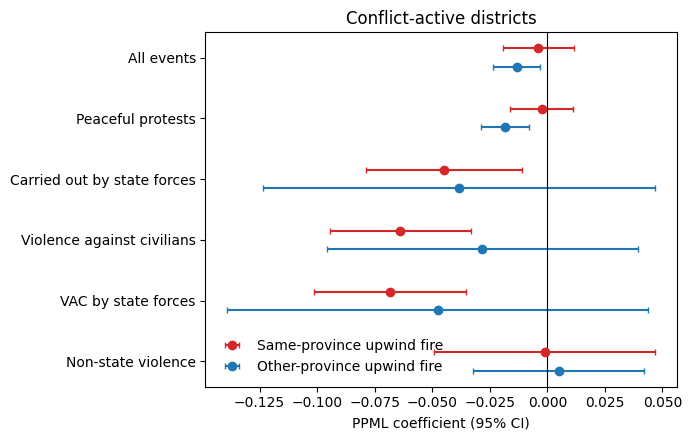

In [7]:
LBL = {'all_events': 'All events', 'peaceful_protest': 'Peaceful protests', 'state_forces': 'Carried out by state forces',
       'vac': 'Violence against civilians', 'vac_state': 'VAC by state forces', 'nonstate_violence': 'Non-state violence'}
p = res[(res['sample'] == 'active') & (res['spec'] == 'A: province') & (res['estimator'] == 'PPML')].set_index('outcome').loc[list(LBL)]
y = np.arange(len(p))[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
for off, term, col, lab in [(0.15, 'log_same', '#d62728', 'Same-province upwind fire'), (-0.15, 'log_other', '#1f77b4', 'Other-province upwind fire')]:
    ax.errorbar(p[term], y + off, xerr=1.96 * p[term + '_se'], fmt='o', color=col, capsize=2, label=lab)
ax.axvline(0, color='k', lw=0.8)
ax.set_yticks(y); ax.set_yticklabels([LBL[o] for o in p.index])
ax.set_xlabel('PPML coefficient (95% CI)'); ax.legend(frameon=False, loc='lower left'); ax.set_title('Conflict-active districts')
fig.tight_layout(); fig.savefig(OUT_PNG, dpi=200); fig.savefig(FIG_PNG, dpi=200); plt.show()